In [84]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.5f}'.format
from sklearn.preprocessing import OneHotEncoder
from category_encoders import CountEncoder
from category_encoders.target_encoder import TargetEncoder

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')


from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression,Ridge,LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


In [35]:
train = pd.read_csv('../data/train.csv')
policies = pd.read_csv('../data/policies.csv')
test = pd.read_csv('../data/test.csv')
samplesubmission = pd.read_csv('../data/SampleSubmission.csv')

In [36]:
categorical = ['product',
       'agent', 'class_of_business', 'risk_type', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch']

In [37]:
data  = pd.concat([train,test],axis=0)

In [38]:
for col in categorical:
    data = pd.concat([data,pd.get_dummies(data[col],drop_first=True)] ,axis=1)

In [39]:
# Convert datetime variables to datetime objects
data.loss_date = pd.to_datetime(data.loss_date, errors='coerce')

# Confirm that the dates have been converted successfully 
data.loss_date.describe()

# Extract day, month and year from the loss date column
# day
data['loss_date_day'] = data.loss_date.dt.day

# day
data['day_of_week'] = data.loss_date.dt.day_of_week

# day
data['week'] = data.loss_date.dt.week

# month
data['loss_date_month'] = data.loss_date.dt.month
 
# year
data['loss_date_year'] = data.loss_date.dt.year

# Preview engineered date features
data[['loss_date', 'loss_date_day', 'loss_date_month', 'loss_date_year','day_of_week','week']].head()

,loss_date,loss_date_day,loss_date_month,loss_date_year,day_of_week,week
0,2021-05-13,13,5,2021,3,19
1,2018-05-13,13,5,2018,6,19
2,2018-08-18,18,8,2018,5,33
3,2018-12-20,20,12,2018,3,51
4,2018-11-07,7,11,2018,2,45


In [40]:
train = data[:9376]
test = data[9376:]
print(train.shape)
print(test.shape)

(9376, 259)
(4019, 259)


In [41]:
to_encode = ['product','primary_cause']
cEncoder = TargetEncoder(cols=to_encode)
cEncoder.fit(train[to_encode],train.target)
train = train.join(cEncoder.transform(train[to_encode]).add_suffix('_count'))
# cEncoder.fit(test[to_encode])
test = test.join(cEncoder.transform(test[to_encode]).add_suffix('_count'))

In [42]:
feature_cols = [col for col in train.columns if col not in ['claim_id', 'policy_number', 'claim_number','product', 'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type', 'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch','target']]

In [77]:
X = train[feature_cols]
y = train.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25, random_state=2001)

In [80]:
model = XGBRegressor(n_estimators=7000,random_state = 2001, learning_rate=0.1, eval_metric='rmse',min_child_samples=12)
model.fit(X_train,y_train,eval_set=[(X_test,y_test)],early_stopping_rounds=200,verbose=200)

[13:51:00] WARNING: ..\src\learner.cc:576: 
Parameters: { "min_child_samples" } might not be used.

  This could be a false alarm, with some parameters getting used by language bindings but
  then being mistakenly passed down to XGBoost core, or some parameter actually being used
  but getting flagged wrongly here. Please open an issue if you find any such cases.


[0]	validation_0-rmse:178170.73438
[200]	validation_0-rmse:200105.53125
[205]	validation_0-rmse:199901.06250


XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             eval_metric='rmse', gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.1, max_delta_step=0,
             max_depth=6, min_child_samples=12, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=7000, n_jobs=4,
             num_parallel_tree=1, predictor='auto', random_state=2001,
             reg_alpha=0, reg_lambda=1, scale_pos_weight=1, subsample=1,
             tree_method='exact', validate_parameters=1, verbosity=None)

In [85]:
model2 = CatBoostRegressor(n_estimators=7000,random_state = 2001, learning_rate=0.1, eval_metric='RMSE',min_child_samples=12)
model2.fit(X_train,y_train,eval_set=[(X_test,y_test)],early_stopping_rounds=200,verbose=200)

0:	learn: 214597.3718276	test: 174364.8757576	best: 174364.8757576 (0)	total: 73.5ms	remaining: 8m 34s
200:	learn: 104174.5620002	test: 168268.6627501	best: 165449.1992836 (23)	total: 2.64s	remaining: 1m 29s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 165449.1993
bestIteration = 23

Shrink model to first 24 iterations.


In [81]:
test_df = test[feature_cols]
predictions = model.predict(test_df)


sub_file = samplesubmission.copy()
sub_file.target = predictions


# Write to csv file to submit to Zindi
sub_file.to_csv("XGBFinalxxx.csv", index = False)

In [86]:
test_df = test[feature_cols]
predictions2 = model2.predict(test_df)


sub_file = samplesubmission.copy()
sub_file.target = predictions2


# Write to csv file to submit to Zindi
sub_file.to_csv("CATFINALxxx.csv", index = False)

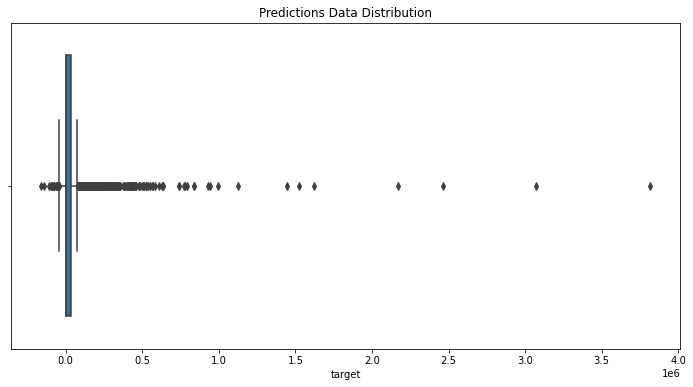

In [68]:
blend = predictions * .5 + predictions2 * .5

sub_file.target = blend

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("FINALBLEND00.csv", index = False)